# Polymer Classification using FTIR Spectroscopy

This notebook explores whether different polymer types can be identified from their Fourier-transform infrared (FTIR) spectra using machine learning (supervised learning).

The goal is to build a reliable classification pipeline that learns patterns from absorbance/transmittance values across the infrared wavelength range and predicts the correct polymer class for each sample. This project is relevant for applications such as plastic sorting, recycling, and materials identification in industrial and laboratory settings.

## Dataset
The FTIR spectra used in this project were obtained from the Kaggle dataset "FTIR Plastic C4" by nhlich2003. The dataset contains spectral measurements for multiple polymer classes and is used to evaluate the performance of machine learning models for polymer recognition.

## Workflow
1. Load and inspect the FTIR dataset
2. Perform exploratory data analysis to understand class distribution and spectral differences
3. Visualize representative spectra for each polymer type
4. Prepare features and labels for model training
5. Train a classifier and evaluate its performance on unseen test data
6. Interpret model behavior and summarize the main findings

## To Do: 
1. Support Vector Machine
2. XGBoost
3. k-Nearest Neighbors
4. Convolutional Neural Network
5. Multi-Layer Perception

# Exploratory Data Analysis (EDA)

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.decomposition import PCA

In [67]:
# FTIR-Data table
df = pd.read_csv("../data/FTIR_PLASTIC_c4.csv")
df.head()

,IDE,Polymer,Technic,Sample,BR,RST,Data(x),Data(y),Data(x).1,Data(y).1,...,Data(x).3731,Data(y).3731,Data(x).3732,Data(y).3732,Data(x).3733,Data(y).3733,Data(x).3734,Data(y).3734,Data(x).3735,Data(y).3735
0,PETFTIR001,PET,FTIR,1,32,4,399.1927,87.9136,400.1569,88.0659,...,3996.7476,108.1940,3997.7119,108.1900,3998.676,108.1840,3999.6404,108.1810,4000.6045,108.1800
1,PETFTIR002,PET,FTIR,2,32,4,399.1927,91.6224,400.1569,91.7740,...,3996.7476,100.5430,3997.7119,100.5440,3998.676,100.5460,3999.6404,100.5470,4000.6045,100.5470
2,PETFTIR003,PET,FTIR,3,32,4,399.1927,85.6125,400.1569,85.9002,...,3996.7476,98.2881,3997.7119,98.3109,3998.676,98.3264,3999.6404,98.3349,4000.6045,98.3400
3,PETFTIR004,PET,FTIR,4,32,4,399.1927,77.2026,400.1569,77.2429,...,3996.7476,108.0470,3997.7119,108.0340,3998.676,108.0280,3999.6404,108.0330,4000.6045,108.0460
4,PETFTIR005,PET,FTIR,5,32,4,399.1927,77.2834,400.1569,77.7001,...,3996.7476,98.6460,3997.7119,98.6630,3998.676,98.6746,3999.6404,98.6804,4000.6045,98.6826


In [68]:
# How many samples per polymertype
print(df.info())
print(df["Polymer"].value_counts())
print("Number of rows, number of columns:", df.shape)

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Columns: 7478 entries, IDE to Data(y).3735
dtypes: float64(7472), int64(3), str(3)
memory usage: 171.2 MB
None
Polymer
PET     500
HDPE    500
PVC     500
LDPE    500
PP      500
PS      500
Name: count, dtype: int64
Number of rows, number of columns: (3000, 7478)


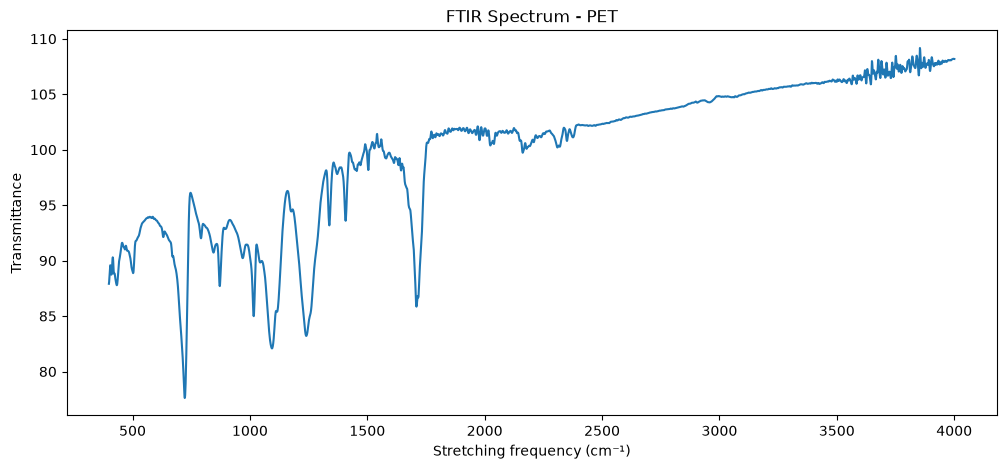

In [69]:
# Spectra of first row polymer: PET

x_cols = [c for c in df.columns if "Data(x)" in c]
y_cols = [c for c in df.columns if "Data(y)" in c]
x = df.loc[0, x_cols].values
y = df.loc[0, y_cols].values

plt.figure(figsize=(12,5))
plt.plot(x,y)
plt.title(f"FTIR Spectrum - {df.loc[0, 'Polymer']}")
plt.xlabel("Stretching frequency (cm⁻¹)")
plt.ylabel("Transmittance")
plt.show()

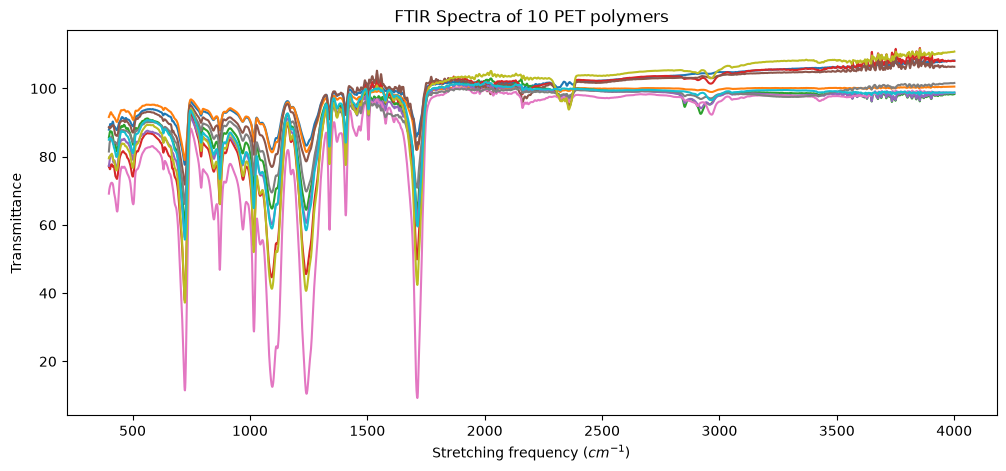

In [70]:
# FTIR spectra of 10 PET samples.
# The characteristic absorption peaks occur at approximately the same wavenumbers for all samples, 
# suggesting a consistent spectral fingerprint for PET.

plt.figure(figsize=(12,5))
for i in range(10):
    x = df.loc[i, x_cols].values
    y = df.loc[i, y_cols].values

    plt.plot(x,y)

plt.title("FTIR Spectra of 10 PET polymers")
plt.xlabel(r"Stretching frequency ($cm^{-1}$)")
plt.ylabel("Transmittance")
plt.show()

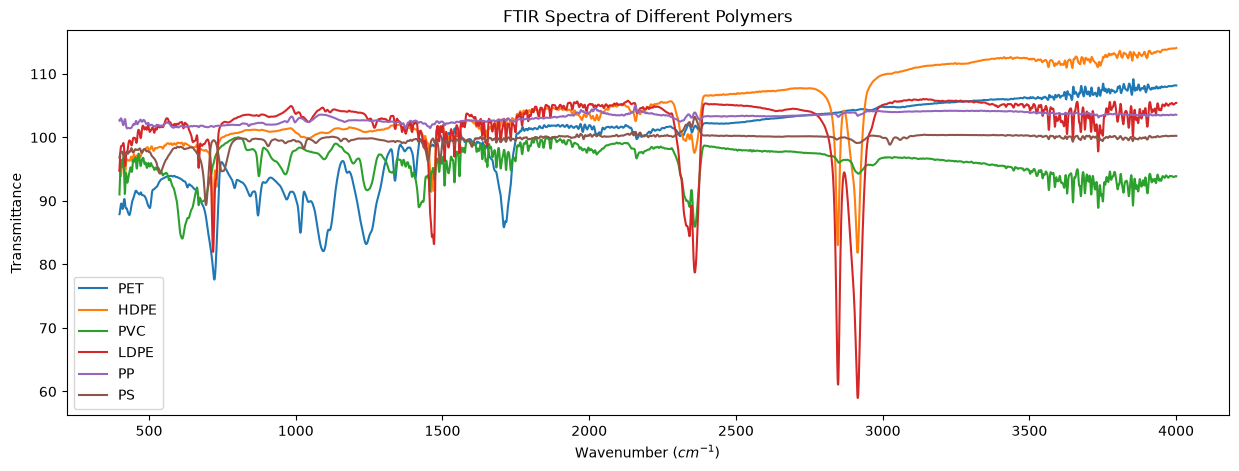

In [71]:
# Comparison of FTIR spectra from six polymer types.
# Characteristic absorption peaks occur at different wavenumbers for each polymer.
# PET, PVC, PP and PS show clearly distinguishable spectral profiles.
# HDPE and LDPE appear more similar than the other polymer pairs.
# Differences in peak position and intensity indicate that the spectra contain information suitable for polymer classification.
# Visual inspection suggests that successful machine learning based classification should be achievable.

polymers = df["Polymer"].unique()

plt.figure(figsize=(15,5))

for polymer in polymers:
    row = df[df["Polymer"] == polymer].iloc[0]
    x = row[x_cols].values
    y = row[y_cols].values

    plt.plot(x, y, label=polymer)

plt.xlabel(r"Wavenumber ($cm^{-1}$)")
plt.ylabel("Transmittance")
plt.title("FTIR Spectra of Different Polymers")
plt.legend()
plt.show()

In [72]:
# Verify that all samples share the same FTIR wavenumber axis.
# FTIR spectra are measured at identical wavenumbers, so the wavelength positions should be the same for every sample.

x1 = df.loc[0, x_cols].values
x2 = df.loc[1, x_cols].values
print((x1 == x2).all())

# Compare the wavenumber axis between two different polymer samples. 
# Different polymers should still use the same measurement wavenumbers, allowing direct comparison of spectral intensities.

x_pet = df[df["Polymer"] == "PET"].iloc[0][x_cols].values
x_pp = df[df["Polymer"] == "PP"].iloc[0][x_cols].values
print((x_pet == x_pp).all())

# Machine learning setup
# X contains the FTIR Transmittance values (spectral features).
# y contains the polymer labels.
# The goal is to train a classifier that predicts the polymer type from its FTIR spectrum.

transmittance_cols = [c for c in df.columns if "Data(y)" in c]

X = df[transmittance_cols]
X.shape
y = df["Polymer"]

print(X.shape)
print(y.shape)

True
True
(3000, 3736)
(3000,)


# Machine Learning

### Random forest model

In [73]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report

# Generating Train/Test split, test size 40%
# Model only sees the train data and testdata is hidden
# Decreasing test data to 20, model yields 100% accuracy. 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.4, random_state= 42, stratify= y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

# Using Random forest model for prediction of polymers.
# Trying to find rules and correlation between certain polymer type vs. transmittance intensity
# For example. If absorbance at 1710 cm^-1 is high --> Propably PET

rf = RandomForestClassifier(n_estimators= 100, random_state= 42)
rf.fit(X_train, y_train )

y_pred = rf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
print(classification_report(y_test, y_pred))

X_train: (1800, 3736)
X_test: (1200, 3736)
y_train: (1800,)
y_test: (1200,)
Accuracy: 0.9950
              precision    recall  f1-score   support

        HDPE       1.00      0.99      0.99       200
        LDPE       1.00      1.00      1.00       200
         PET       1.00      1.00      1.00       200
          PP       0.99      1.00      1.00       200
          PS       0.98      1.00      0.99       200
         PVC       1.00      0.98      0.99       200

    accuracy                           0.99      1200
   macro avg       1.00      1.00      0.99      1200
weighted avg       1.00      0.99      0.99      1200



Text(0.5, 1.0, 'Confusion Matrix Random Forest -model')

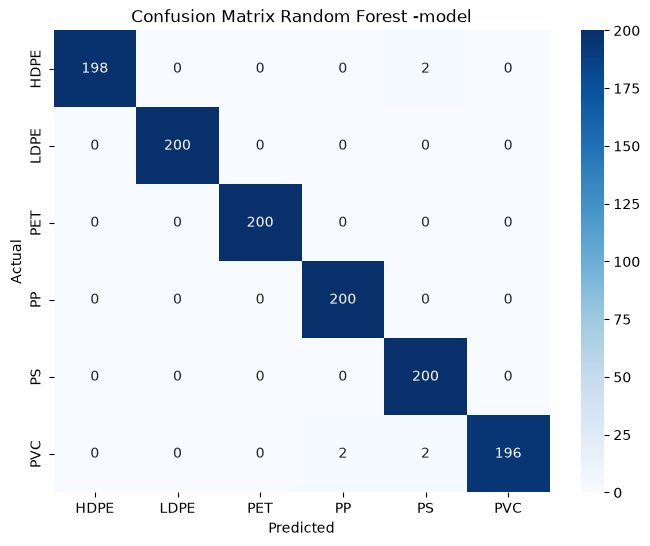

In [74]:
# Confusion matrix visualization for Random Forest predictions.
# Rows represent the true polymer classes and columns represent the predicted classes. 
# Values on the diagonal indicate correct classifications, while off-diagonal values represent misclassifications between polymer types.

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels= rf.classes_, yticklabels=rf.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Random Forest -model")

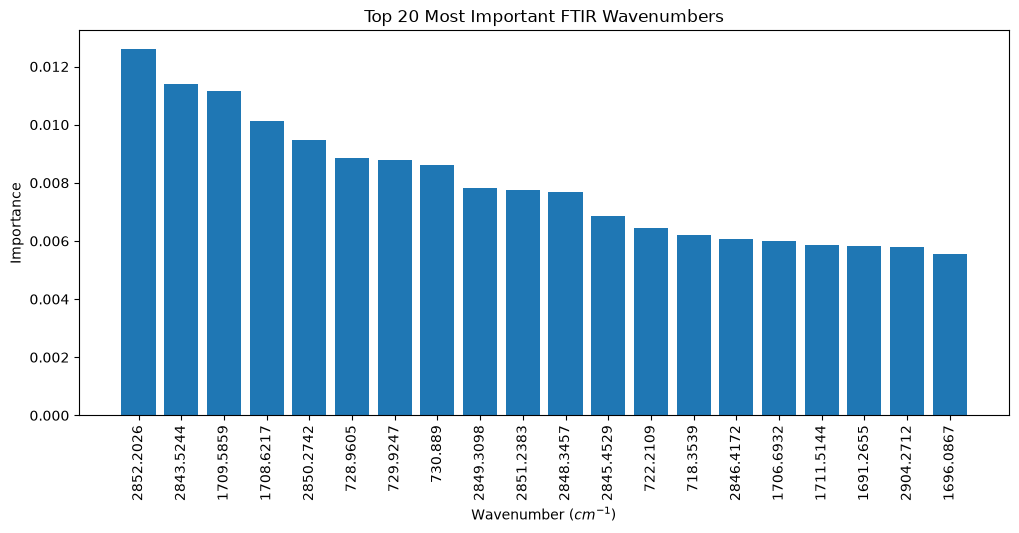

In [75]:
# Most important wavelengths.
# The most important spectral regions are associated with characteristic polymer absorption bands, 
# including aliphatic C-H stretching (~2850 cm⁻¹) and carbonyl C=O stretching (~1710 cm⁻¹).

rf.feature_importances_
wavenumbers = df.loc[0, x_cols].values

importance_df = pd.DataFrame({
    "Wavenumber": wavenumbers,
    "Importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by= "Importance",
    ascending= False
)

top20 = importance_df.head(20)

plt.figure(figsize=(12,5))
plt.bar(top20["Wavenumber"].astype(str),
        top20["Importance"])

plt.xticks(rotation=90)
plt.xlabel(r"Wavenumber ($cm^{-1}$)")
plt.ylabel("Importance")
plt.title("Top 20 Most Important FTIR Wavenumbers")
plt.show()

In [ ]:
# Are task really hard to complete or is data easily separable?

# Label-shuffle-test
y_shuffled = y.sample(frac= 1, random_state=42).reset_index(drop= True)
X_train, X_test, y_train, y_test = train_test_split(X, y_shuffled, test_size=0.2, random_state=42)

rf_shuffle = RandomForestClassifier(n_estimators= 100, random_state= 42)

rf_shuffle.fit(X_train, y_train)

y_pred_shuffle = rf_shuffle.predict(X_test)

shuffle_accuracy = accuracy_score(y_test, y_pred_shuffle)
print("Shuffle accuracy:", shuffle_accuracy)
print(classification_report(y_test,y_pred_shuffle))

0.155
              precision    recall  f1-score   support

        HDPE       0.18      0.15      0.17       117
        LDPE       0.11      0.14      0.12        87
         PET       0.20      0.17      0.19       115
          PP       0.15      0.18      0.16        90
          PS       0.17      0.16      0.16        95
         PVC       0.12      0.12      0.12        96

    accuracy                           0.15       600
   macro avg       0.16      0.15      0.15       600
weighted avg       0.16      0.15      0.16       600



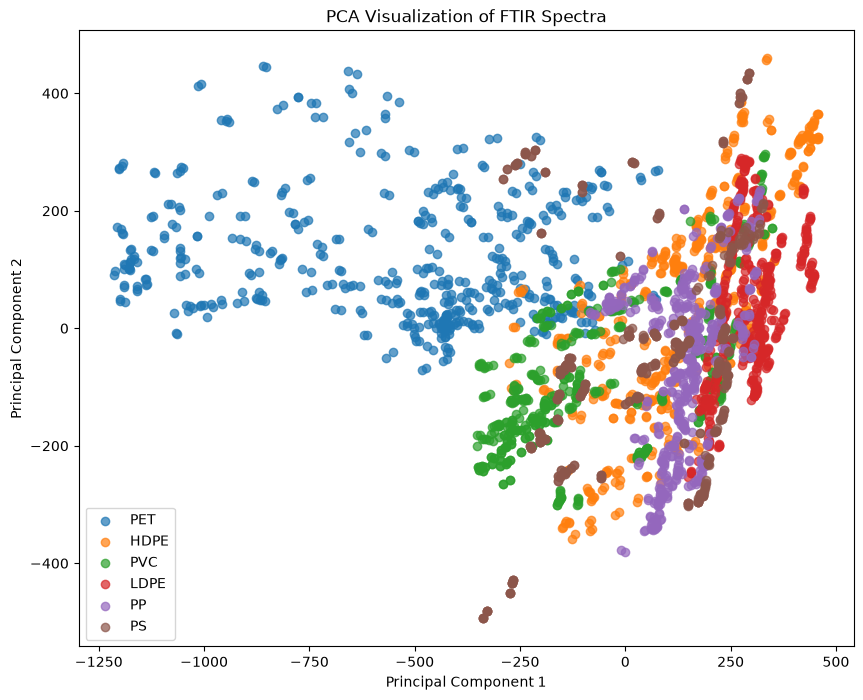

In [77]:
# PCA visualization reveals clear separation between several polymer classes.
# PET forms a distinct cluster, indicating strong spectral differences compared to the other polymers.
# HDPE, LDPE and PP exhibit partial overlap in the first two principal components, suggesting greater spectral similarity.
# Despite some overlap in the 2D PCA projection, Random Forest achieved 
# near-perfect classification accuracy using the full 3736-dimensional feature space.

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(10, 8))

for polymer in y.unique():

    mask = y == polymer

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=polymer,
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of FTIR Spectra")
plt.legend()

plt.show()


In [78]:
# 5-fold cross-validation for Random Forest.
# The model achieved a mean accuracy of 99.7% with very low variation between folds (std ≈ 0.16%), indicating excellent
# robustness and stable performance across different train/test splits.

scores = cross_val_score(
    rf,
    X,
    y,
    cv=5
)

print('Scores:', scores)
print('Mean:', scores.mean())
print('Std:', scores.std())

Scores: [0.99666667 0.99666667 0.99666667 0.995      1.        ]
Mean: 0.9970000000000001
Std: 0.001632993161855449


### SVM

In [79]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report

# Random Forest outperformed SVM on the FTIR dataset.
# While both models achieved high accuracy, Random Forest
# produced more accurate predictions on unseen samples.

svm = SVC()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42, stratify= y)

svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
accuracy_score(y_test, y_pred_svm)

0.9733333333333334

In [80]:
# Five-fold cross-validation was used to evaluate model robustness.
# The SVM classifier achieved a mean accuracy of 97.8% with a standard deviation of 0.4%, indicating stable performance across
# different train-test splits.

scores = cross_val_score(svm, X, y, cv=5)
print("Scores:", scores)
print("Mean:", scores.mean())
print("Std:", scores.std())

Scores: [0.975      0.98333333 0.97166667 0.97666667 0.98166667]
Mean: 0.9776666666666666
Std: 0.004294699575575031


### Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter= 100)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42, stratify= y)

lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)
accuracy_score(y_test, y_pred_lr)

c:\projektit\Polymer_classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.915

In [82]:
scores_lr = cross_val_score(lr, X, y, cv=5)

print("Scores:", scores_lr)
print("Mean:", scores_lr.mean())
print("Std:", scores_lr.std())

c:\projektit\Polymer_classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\projektit\Polymer_classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules

Scores: [0.93833333 0.95       0.94       0.95       0.93      ]
Mean: 0.9416666666666667
Std: 0.0076011695006608865


c:\projektit\Polymer_classification\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
